# Can the ten-qubit PP PQDQN learn CartPole?

One matched seed (7), **400 training episodes per backend**: QASP `lightning.pp` with weight cutoff k=2 versus `lightning.qubit` with adjoint differentiation. Both start from the same saved initial weights of the ten-qubit simulator benchmark.

The circuit has four YZ/reuploading layers and CNOT rings including the final layer. Ten shared Z expectations feed a biased two-action affine head. CartPole supplies four observations: six zeros are appended before the model's tanh transform. Thus input scaling coefficients on padded features have zero input; the ten-qubit entangling circuit is unchanged. PP coefficient/top-M pruning is disabled.

This is an exploratory **one-seed** learning comparison, separate from the simulator timing benchmark and the earlier five-seed four-qubit readout study. Running this notebook only reads saved results; it does not start training.

**Cancelled at the user's request on 14 October 2026.** Both workers are stopped and completion monitoring is paused. Partial results and full checkpoints remain saved. Completed checkpoint episodes: pp_k2: 144/400, lightning_qubit: 83/400. Outputs below show an earlier progress snapshot, not final experiment results.

Experiment status: running
Episodes per backend: 400 Seed: 7


lr                         0.01
gamma                      0.99
batch_size                   64
replay_capacity           10000
learning_starts             256
train_frequency               4
gradient_steps                1
target_update_interval      100
double_dqn                 True
epsilon_start               1.0
epsilon_end                0.05
epsilon_decay_steps        8000
max_steps                   500
max_grad_norm              10.0
Name: Training settings, dtype: object

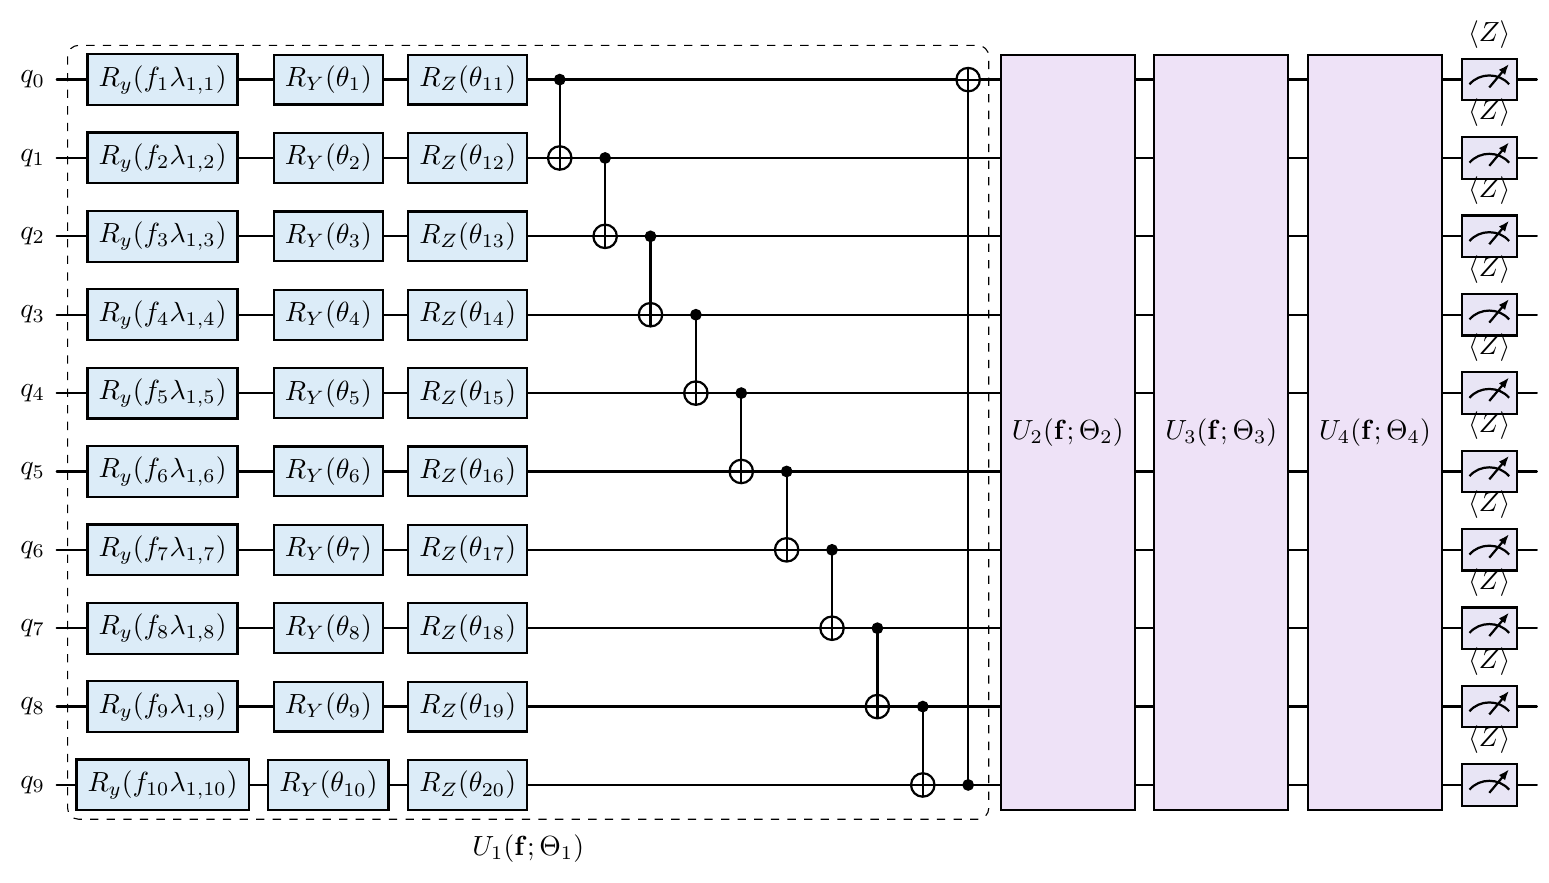

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd() if (Path.cwd() / "qasp").exists() else Path.cwd().parent
DATA = ROOT / "examples/results/pqdqn_pp_vs_lightning_cartpole_10qubit_seed7_400ep"
manifest = json.loads((DATA / "manifest.json").read_text())
status = json.loads((DATA / "finalization_status.json").read_text())
print("Experiment status:", status["status"])
print("Episodes per backend:", manifest["episodes"], "Seed:", manifest["seed"])
display(pd.Series(manifest["training"], name="Training settings"))
display(Image(filename=str(DATA / "drawings/circuit.png")))

## Training curves

Trailing 20-episode means are computed separately for each backend, with the first 19 episodes omitted. There is one curve per trained model and no across-seed confidence band. Initial exploration is scheduled by environment frames, so different trajectories can make epsilon differ at the same episode.

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.2))
progress = []
for backend in ("pp_k2", "lightning_qubit"):
    folder = DATA / backend
    progress.append({"backend": backend, **json.loads((folder / "status.json").read_text())})
    if (folder / "training.csv").exists():
        history = pd.read_csv(folder / "training.csv")
        ax.plot(history["episode"], history["return"].rolling(20, min_periods=20).mean(), label=backend)
ax.set(xlabel="Training episode", ylabel="Trailing 20-episode return")
ax.legend()
ax.grid(alpha=.2)
plt.show()
display(pd.DataFrame(progress))

/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_52466/3903177263.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,backend,status,pid,updated_utc,episode,frames,updates,training_seconds,last_20_mean
0,pp_k2,training,50836,2026-10-14T10:25:45.991615+00:00,15,331,19,73.318954,22.066667
1,lightning_qubit,training,50837,2026-10-14T10:25:18.581523+00:00,13,276,6,42.625887,21.230769


## Greedy evaluation and time

Initial/final evaluations share 20 reset seeds starting at 20000. Held-out evaluation uses 100 reset seeds starting at 30000. Evaluation episode variability is not uncertainty across independently trained models. Training wall times exclude evaluation and checkpoint I/O, but the two workers execute concurrently and may collect different numbers of frames/updates; these times are not a controlled backend speed comparison.

In [3]:
rows = []
for backend in ("pp_k2", "lightning_qubit"):
    marker = DATA / backend / "summary.json"
    if marker.exists():
        summary = json.loads(marker.read_text())
        rows.append({k: summary[k] for k in (
            "backend", "episodes", "frames", "updates", "initial_greedy_mean",
            "final_greedy_mean", "held_out_mean", "held_out_episode_sd",
            "last_20_training_mean", "training_seconds")})
if len(rows) == 2:
    display(pd.DataFrame(rows))
    for backend in ("pp_k2", "lightning_qubit"):
        history = pd.read_csv(DATA / backend / "training.csv")
        evaluation = pd.read_csv(DATA / backend / "evaluation.csv")
        assert history["episode"].tolist() == list(range(1, 401))
        assert evaluation.groupby("phase").size().to_dict() == {"initial": 20, "final": 20, "held_out": 100}
    print("Both 400-episode runs and evaluation counts verified.")
else:
    print("Training/evaluation is still in progress; no completed comparison yet.")
    if rows:
        display(pd.DataFrame(rows))

Training/evaluation is still in progress; no completed comparison yet.


## Reproduction and interpretation

`examples/pqdqn_pp_cartpole_comparison.py` runs and collects the experiment. The directory contains the common initial state, manifest, source snapshot/hashes, raw histories, evaluations, atomic per-episode checkpoints, final trained weights and summaries. Checkpoints include online/target weights, optimizer, replay, counters, history and RNG state; two smoke checks verified identical continuation after restoring either backend.

Do not start another runner while either worker is active. If interrupted, the runner/worker locks and matching manifest guard against duplicate or incompatible continuation.

Assess improvement using the actual initial, final and held-out returns together with the learning curves. This single seed cannot establish general reliability, superiority, or equivalence of PP training. The simulator benchmark's low gradient similarity does not by itself determine the outcome of this empirical learning run.